## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [51]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\masii\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [52]:
import pandas as pd
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [53]:
import matplotlib.pyplot as plt

---

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

---

In [54]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [55]:
frequency_table = df["category"].value_counts()

print(frequency_table)

top_5_categories = frequency_table.head(5)
print("\nTop 5 Most Listed Product Categories:")
print(top_5_categories)


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

Top 5 Most Listed Product Categories:
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


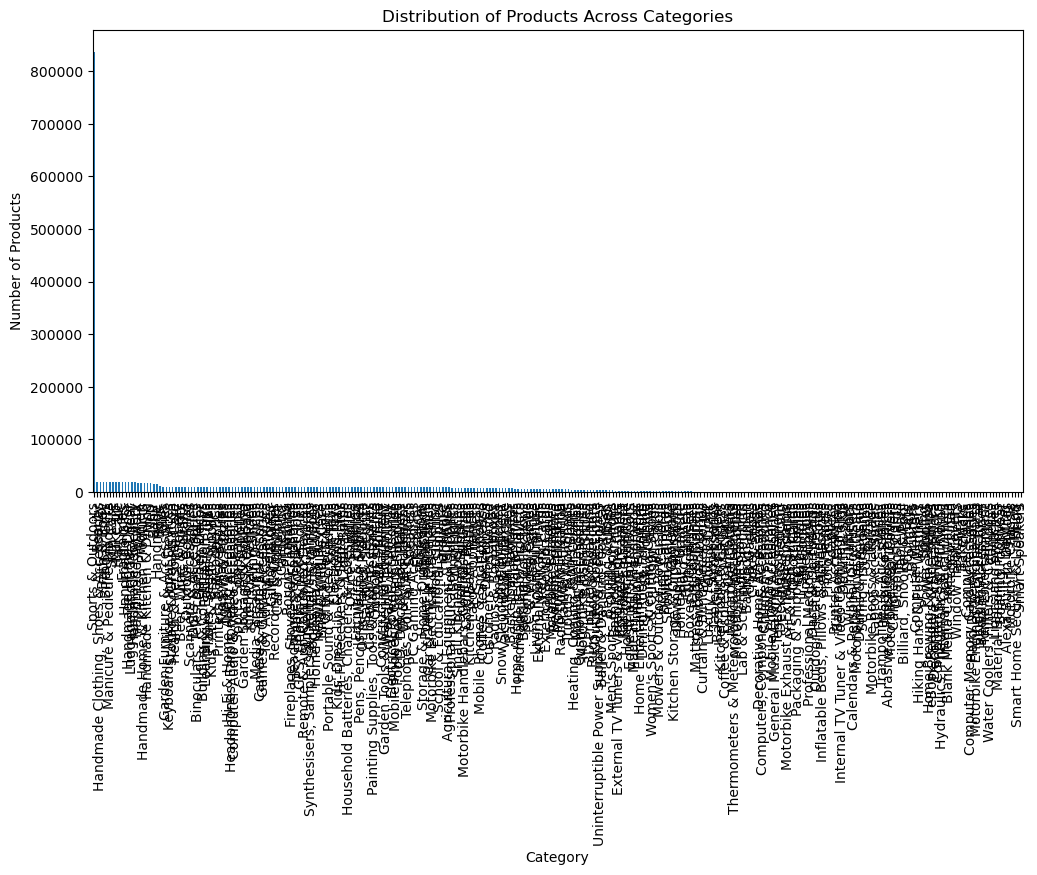

In [56]:
plt.figure(figsize=(12, 6))
frequency_table.plot(kind='bar')
plt.title("Distribution of Products Across Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.show()
# This plot chart is horrendous, I cannot see anything. Will do with top 5 categories.

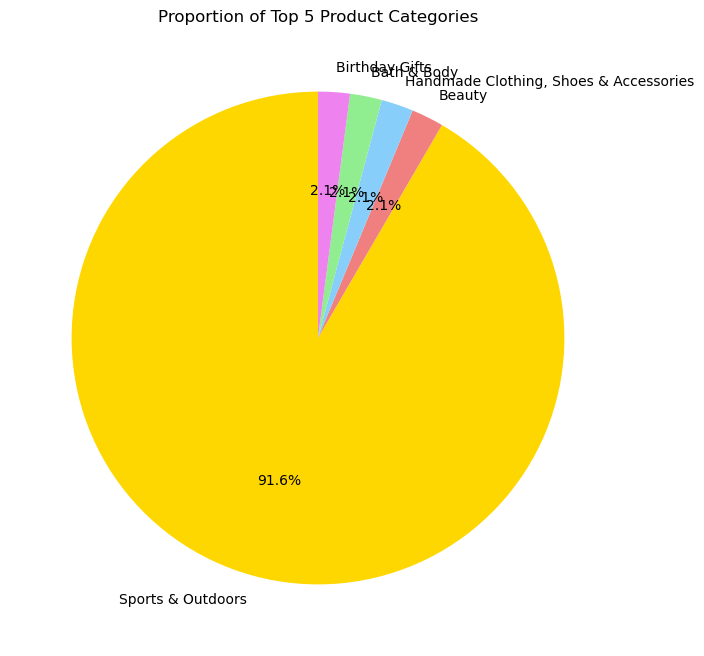

In [58]:
plt.figure(figsize=(8, 8))
top_5_categories.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['gold', 'lightcoral', 'lightskyblue', 'lightgreen', 'violet'])
plt.title("Proportion of Top 5 Product Categories")
plt.ylabel("")
plt.show()
# As most of the priducts are from "Sports and Ourdoors" this kind of charts are useless.

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

---

In [59]:
mean_price = df["price"].mean()
# median_price = df["price"].median()
mode_price = df["price"].mode()[0]

print(f"Mean Price: {mean_price}")
print(f"Median Price: {median_price}")
print(f"Mode Price: {mode_price}")
# These values suggest there are likely some high-priced products that pull the mean up, but the median and mode are much lower, indicating that many products are priced relatively low.

Mean Price: 89.24380943923663
Median Price: 19.08
Mode Price: 9.99


In [60]:
variance_price = df["price"].var()
std_dev_price = df["price"].std()
range_price = df["price"].max() - df["price"].min()
iqr_price = df["price"].quantile(0.75) - df["price"].quantile(0.25)

print(f"Variance: {variance_price}")
print(f"Standard Deviation: {std_dev_price}")
print(f"Range: {range_price}")
print(f"Interquartile Range (IQR): {iqr_price}")

# The variance tells us that the prices are highly dispersed around the mean. A high variance suggests a large spread in the dataset.
# It could be due to the large range.
# The middle 50% of prices are within a much smaller range. This shows that most prices are closer together, despite some extreme outliers.

Variance: 119445.48532256528
Standard Deviation: 345.60886175352226
Range: 100000.0
Interquartile Range (IQR): 36.0


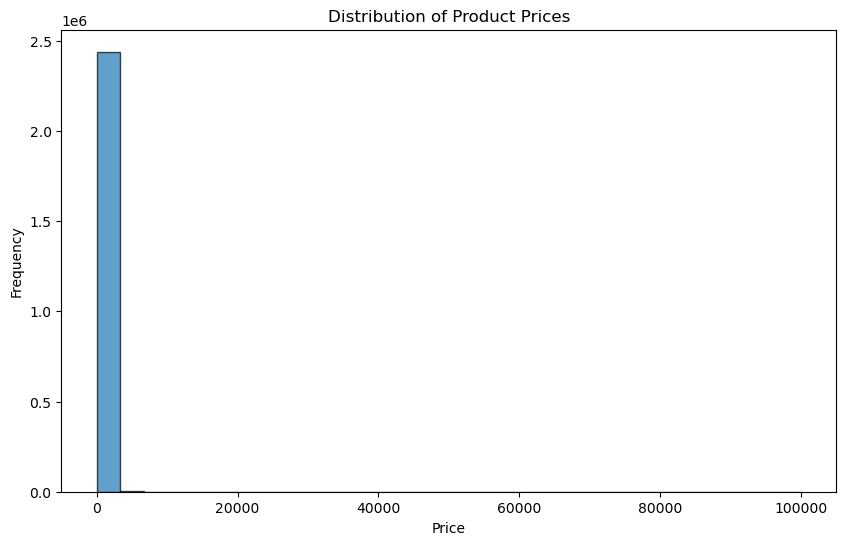

In [61]:
plt.figure(figsize=(10, 6))
plt.hist(df["price"], bins=30, edgecolor='k', alpha=0.7)
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

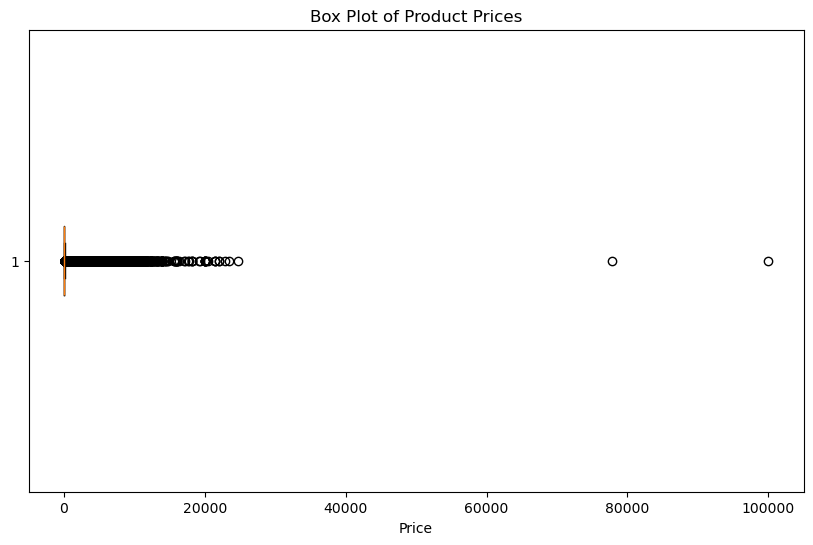

In [62]:
plt.figure(figsize=(10, 6))
plt.boxplot(df["price"], vert=False)
plt.title("Box Plot of Product Prices")
plt.xlabel("Price")
plt.show()

In [ ]:
# I will delete outliers up to, i believe around 200 (as the mean price is around 90, should be alright) I will do the same graphics.
df = df[df["price"] <= 200]

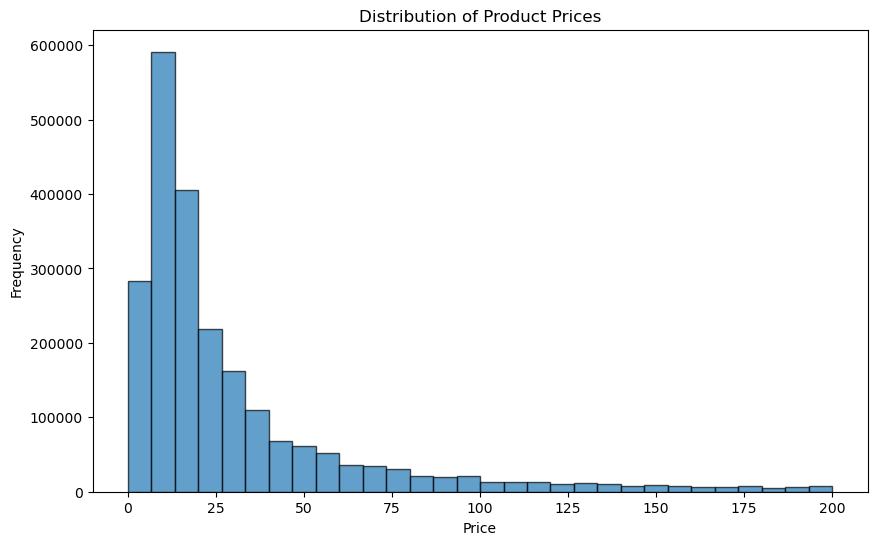

In [65]:
plt.figure(figsize=(10, 6))
plt.hist(df["price"], bins=30, edgecolor='k', alpha=0.7)
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

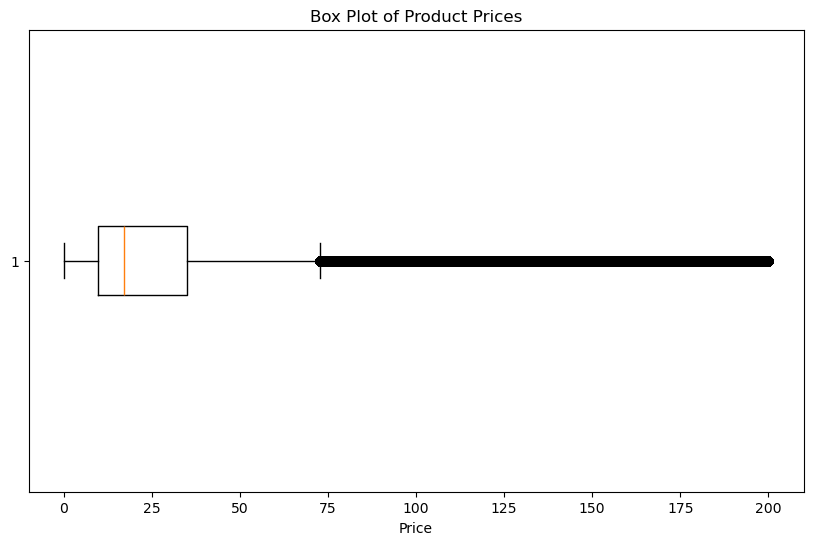

In [ ]:
plt.figure(figsize=(10, 6))
plt.boxplot(df["price"], vert=False)
plt.title("Box Plot of Product Prices")
plt.xlabel("Price")
plt.show() 
# At least we can see now the box :D

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

---

In [ ]:
mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()[0]

print(f"Mean Rating: {mean_rating}")
print(f"Median Rating: {median_rating}")
print(f"Mode Rating: {mode_rating}")
# There is a lot of "0" for those products, as the mode is 0. mean and median are average (asuming it is a 5 star rating)


Mean Rating: 2.250047763303825
Median Rating: 3.2
Mode Rating: 0.0


In [ ]:
variance_rating = df["stars"].var()
std_dev_rating = df["stars"].std()
iqr_rating = df["stars"].quantile(0.75) - df["stars"].quantile(0.25)

print(f"Variance: {variance_rating}")
print(f"Standard Deviation: {std_dev_rating}")
print(f"Interquartile Range (IQR): {iqr_rating}")
# The product ratings show a moderate degree of variability. There is a spread in how customers rate the products, with some significant differences observed in the middle 50% of ratings. 
# # This suggests that while many customers might rate products similarly, there are enough differing opinions to create a broad range.

Variance: 4.815823383940277
Standard Deviation: 2.194498435620376
Interquartile Range (IQR): 4.4


In [ ]:
from scipy.stats import skew, kurtosis

skewness = skew(df["stars"])
kurt = kurtosis(df["stars"])

print(f"Skewness: {skewness}")
print(f"Kurtosis: {kurt}")
# The product ratings on Amazon UK are quite evenly distributed, with no strong tendency towards high or low ratings.
# The ratings form a near-symmetrical distribution, and there are fewer extreme ratings, indicating a consistent pattern in customer feedback.

Skewness: -0.005958058778146425
Kurtosis: -1.9301352771819595


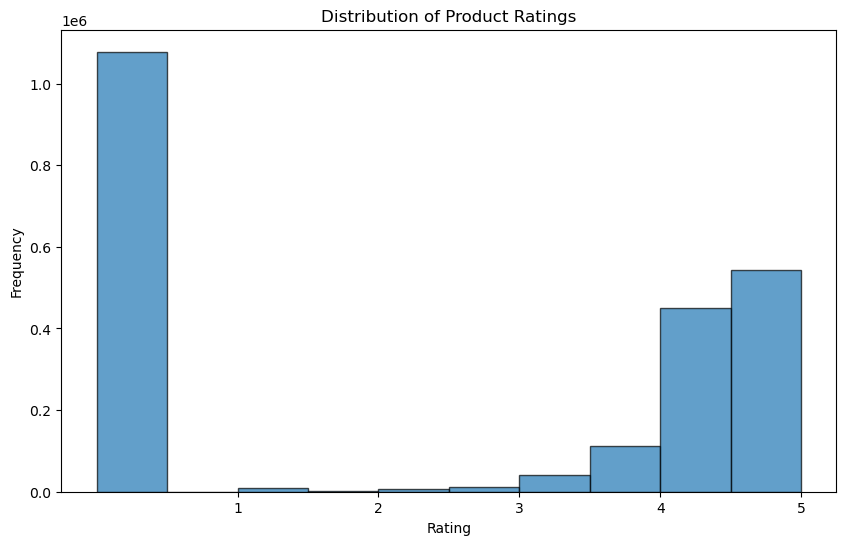

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df["stars"], bins=10, edgecolor='k', alpha=0.7)
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.xticks(range(1, 6))
plt.show()
# People love the hate. There are a LOT of "0" that might even be because the product had a late delivery or came broken (which in my opinion, has nothing to do with the product itself).